<a href="https://www.kaggle.com/code/lalit7881/ai-adoption-workplace-productivity-eda?scriptVersionId=361649525" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/eishatuzzuhra/ai-agent-adoption-and-workplaceproductivity20242026/AI_Agent_Adoption_Workplace_Productivity_2024_2026.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/eishatuzzuhra/ai-agent-adoption-and-workplaceproductivity20242026/AI_Agent_Adoption_Workplace_Productivity_2024_2026.csv")

In [3]:
df.head()

,Record_ID,Year,Country,Industry,Company_Size,Job_Role,Age_Group,AI_Agent_Usage,AI_Agent_Type,Tasks_Automated,...,AI_Skill_Level,Training_Hours,Monthly_AI_Cost,Job_Satisfaction,Workload_Level,Trust_in_AI,Human_AI_Collaboration,Error_Rate,Job_Risk_Level,Overall_AI_Impact
0,AIW-0001,2025,France,Finance & Banking,Enterprise (1000+),Sales Representative,35-44,High,WORKFLOW AUTOMATION AGENT,43.0,...,Intermediate,15.0,44.39,7.0,Moderate,6.0,High,7.0,Moderate,Positive
1,AIW-0002,2025,Germany,Energy & Utilities,Medium (51-250),Software Engineer,45-54,Very High,Coding Agent,31.0,...,Intermediate,2.0,161.80,8.0,Low,7.0,High,5.4,Very High,Positive
2,AIW-0003,2025,Germany,Logistics & Supply Chain,Enterprise (1000+),Legal & Compliance Officer,55+,Low,Data Processing Agent,6.0,...,Beginner,25.0,41.80,10.0,Moderate,6.0,Moderate,6.7,Low,Positive
3,AIW-0004,2025,France,Logistics & Supply Chain,Enterprise (1000+),Legal & Compliance Officer,35-44,High,Content Generation Agent,16.0,...,Advanced,59.0,42.40,5.0,High,6.0,High,8.2,Moderate,Neutral
4,AIW-0005,2024,India,Finance & Banking,Enterprise (1000+),HR Specialist,25-34,High,Scheduling & Admin Agent,23.0,...,Intermediate,0.0,27.01,NaN,Moderate,5.0,Moderate,9.6,Moderate,Neutral


In [4]:
df.tail()

,Record_ID,Year,Country,Industry,Company_Size,Job_Role,Age_Group,AI_Agent_Usage,AI_Agent_Type,Tasks_Automated,...,AI_Skill_Level,Training_Hours,Monthly_AI_Cost,Job_Satisfaction,Workload_Level,Trust_in_AI,Human_AI_Collaboration,Error_Rate,Job_Risk_Level,Overall_AI_Impact
518,AIW-0519,2026,South Africa,Telecommunications,Enterprise (1000+),Sales Representative,35-44,Moderate,Multi-Agent System,24.0,...,Intermediate,3.0,133.26,7.0,Moderate,4.0,Moderate,8.9,High,Neutral
519,AIW-0520,2025,United States,Technology,Small (1-50),Sales Representative,45-54,Moderate,Content Generation Agent,21.0,...,Intermediate,NaN,37.90,8.0,High,6.0,Moderate,7.5,High,Positive
520,AIW-0521,2026,Brazil,Retail & E-commerce,Small (1-50),Marketing Specialist,25-34,Moderate,Content Generation Agent,8.0,...,Beginner,0.0,31.37,7.0,Low,4.0,Low,7.8,High,Positive
521,AIW-0522,2025,India,Education,Medium (51-250),Product Manager,35-44,Moderate,Content Generation Agent,13.0,...,Intermediate,19.0,28.71,7.0,Moderate,5.0,Moderate,5.1,Moderate,Highly Positive
522,AIW-0523,2025,Pakistan,Telecommunications,Medium (51-250),Financial Analyst,25-34,Moderate,Research & Analysis Agent,10.0,...,Intermediate,1.0,67.56,7.0,Moderate,5.0,Low,12.2,High,Neutral


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 523 entries, 0 to 522
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Record_ID                    523 non-null    object 
 1   Year                         523 non-null    int64  
 2   Country                      523 non-null    object 
 3   Industry                     523 non-null    object 
 4   Company_Size                 523 non-null    object 
 5   Job_Role                     523 non-null    object 
 6   Age_Group                    515 non-null    object 
 7   AI_Agent_Usage               523 non-null    object 
 8   AI_Agent_Type                523 non-null    object 
 9   Tasks_Automated              518 non-null    float64
 10  Hours_Saved_Per_Week         515 non-null    float64
 11  Productivity_Change_Percent  517 non-null    float64
 12  AI_Skill_Level               520 non-null    object 
 13  Training_Hours      

In [6]:
df.describe()

,Year,Tasks_Automated,Hours_Saved_Per_Week,Productivity_Change_Percent,Training_Hours,Monthly_AI_Cost,Job_Satisfaction,Trust_in_AI,Error_Rate
count,523.000000,518.000000,515.000000,517.000000,508.000000,517.000000,511.00000,514.000000,505.000000
mean,2025.187380,33.171815,6.882718,10.256867,19.039370,102.845667,6.60274,5.566148,9.310693
std,0.782516,34.641957,7.115016,15.328102,26.122199,327.181275,1.77032,1.603025,5.513789
min,2024.000000,0.000000,0.000000,-41.500000,-8.000000,0.000000,0.00000,1.000000,2.200000
25%,2025.000000,11.000000,2.100000,0.800000,6.000000,28.250000,5.00000,4.000000,6.400000
50%,2025.000000,23.000000,4.300000,8.100000,13.000000,57.720000,7.00000,6.000000,8.200000
75%,2026.000000,42.750000,9.000000,18.800000,25.000000,111.070000,8.00000,7.000000,10.900000
max,2026.000000,391.000000,36.500000,128.300000,335.000000,6075.960000,10.00000,11.000000,67.200000


In [7]:
df.isnull().sum()

Record_ID                       0
Year                            0
Country                         0
Industry                        0
Company_Size                    0
Job_Role                        0
Age_Group                       8
AI_Agent_Usage                  0
AI_Agent_Type                   0
Tasks_Automated                 5
Hours_Saved_Per_Week            8
Productivity_Change_Percent     6
AI_Skill_Level                  3
Training_Hours                 15
Monthly_AI_Cost                 6
Job_Satisfaction               12
Workload_Level                  0
Trust_in_AI                     9
Human_AI_Collaboration          0
Error_Rate                     18
Job_Risk_Level                  0
Overall_AI_Impact               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

Record_ID                       object
Year                             int64
Country                         object
Industry                        object
Company_Size                    object
Job_Role                        object
Age_Group                       object
AI_Agent_Usage                  object
AI_Agent_Type                   object
Tasks_Automated                float64
Hours_Saved_Per_Week           float64
Productivity_Change_Percent    float64
AI_Skill_Level                  object
Training_Hours                 float64
Monthly_AI_Cost                float64
Job_Satisfaction               float64
Workload_Level                  object
Trust_in_AI                    float64
Human_AI_Collaboration          object
Error_Rate                     float64
Job_Risk_Level                  object
Overall_AI_Impact               object
dtype: object

In [10]:
df.shape

(523, 22)

In [11]:
df.columns

Index(['Record_ID', 'Year', 'Country', 'Industry', 'Company_Size', 'Job_Role',
       'Age_Group', 'AI_Agent_Usage', 'AI_Agent_Type', 'Tasks_Automated',
       'Hours_Saved_Per_Week', 'Productivity_Change_Percent', 'AI_Skill_Level',
       'Training_Hours', 'Monthly_AI_Cost', 'Job_Satisfaction',
       'Workload_Level', 'Trust_in_AI', 'Human_AI_Collaboration', 'Error_Rate',
       'Job_Risk_Level', 'Overall_AI_Impact'],
      dtype='object')

In [12]:
df.nunique()

Record_ID                      523
Year                             3
Country                         28
Industry                        20
Company_Size                    12
Job_Role                        21
Age_Group                        9
AI_Agent_Usage                  11
AI_Agent_Type                   15
Tasks_Automated                108
Hours_Saved_Per_Week           160
Productivity_Change_Percent    328
AI_Skill_Level                  11
Training_Hours                  71
Monthly_AI_Cost                497
Job_Satisfaction                10
Workload_Level                   8
Trust_in_AI                     11
Human_AI_Collaboration           9
Error_Rate                     145
Job_Risk_Level                   5
Overall_AI_Impact               10
dtype: int64

## EDA

Dataset Shape: (523, 22)

Missing Values:
 Record_ID                       0
Year                            0
Country                         0
Industry                        0
Company_Size                    0
Job_Role                        0
Age_Group                       8
AI_Agent_Usage                  0
AI_Agent_Type                   0
Tasks_Automated                 5
Hours_Saved_Per_Week            8
Productivity_Change_Percent     6
AI_Skill_Level                  3
Training_Hours                 15
Monthly_AI_Cost                 6
Job_Satisfaction               12
Workload_Level                  0
Trust_in_AI                     9
Human_AI_Collaboration          0
Error_Rate                     18
Job_Risk_Level                  0
Overall_AI_Impact               0
dtype: int64

Data Types:
 Record_ID                       object
Year                             int64
Country                         object
Industry                        object
Company_Size              

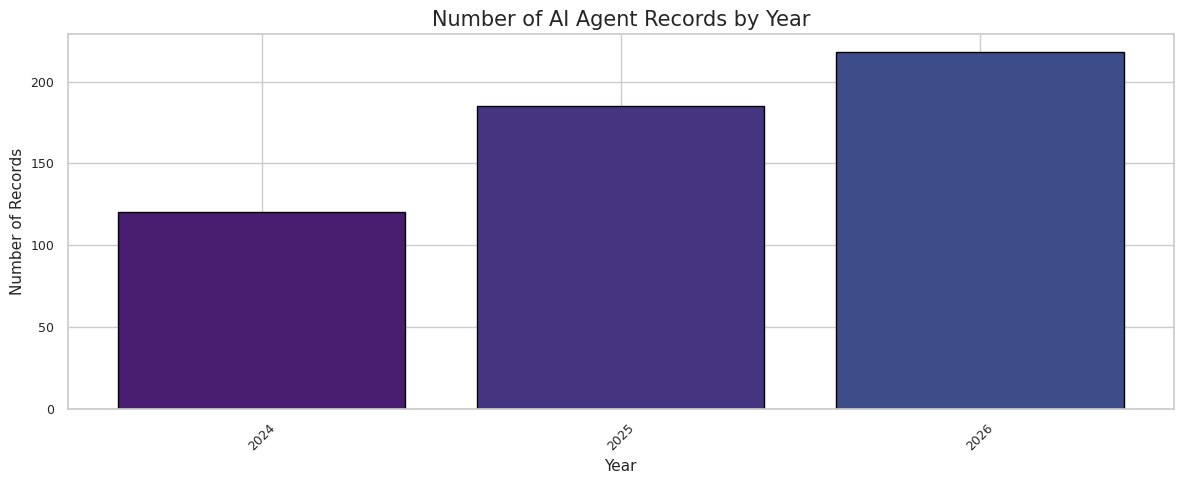

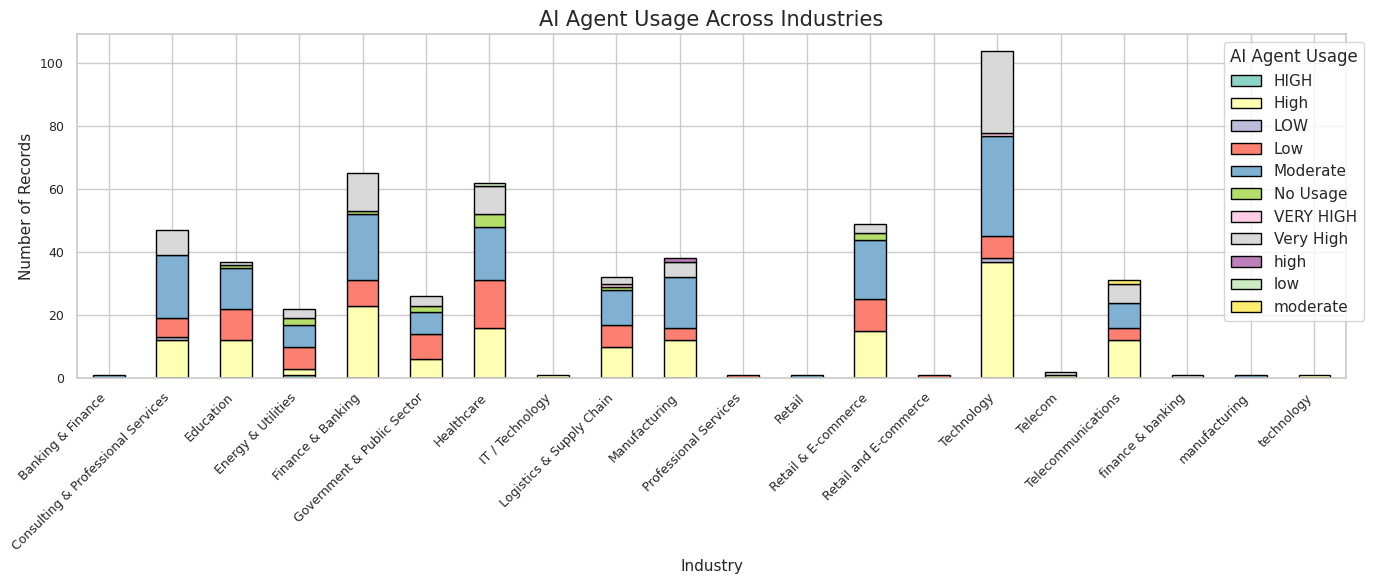

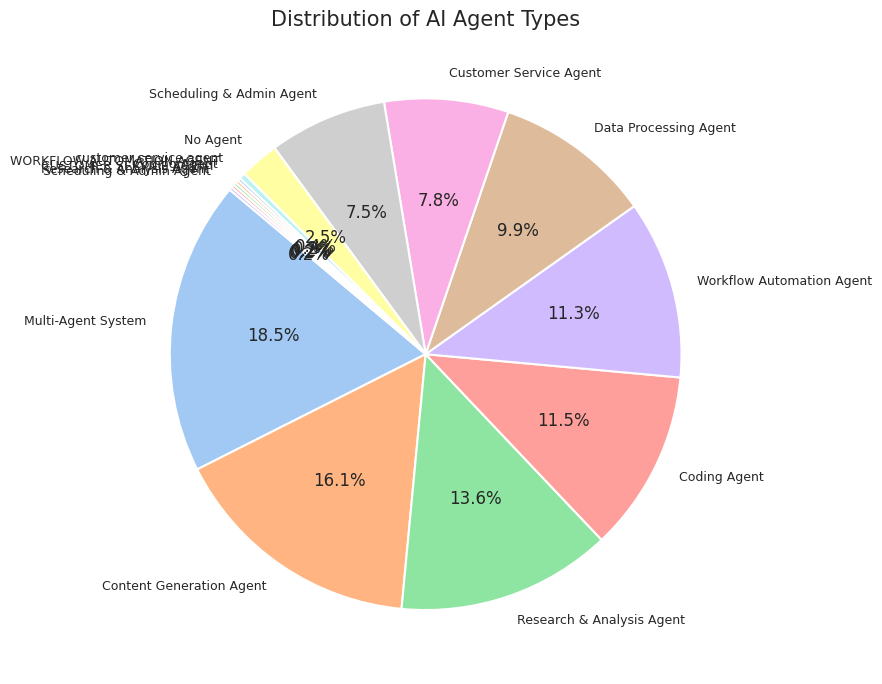

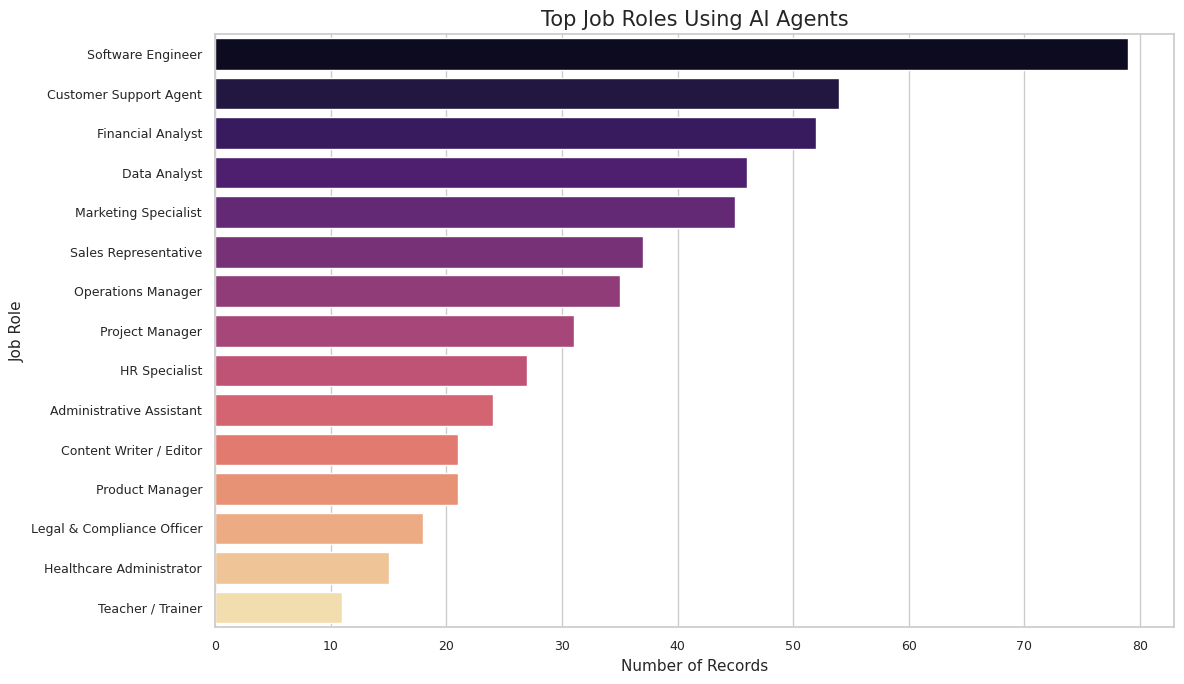

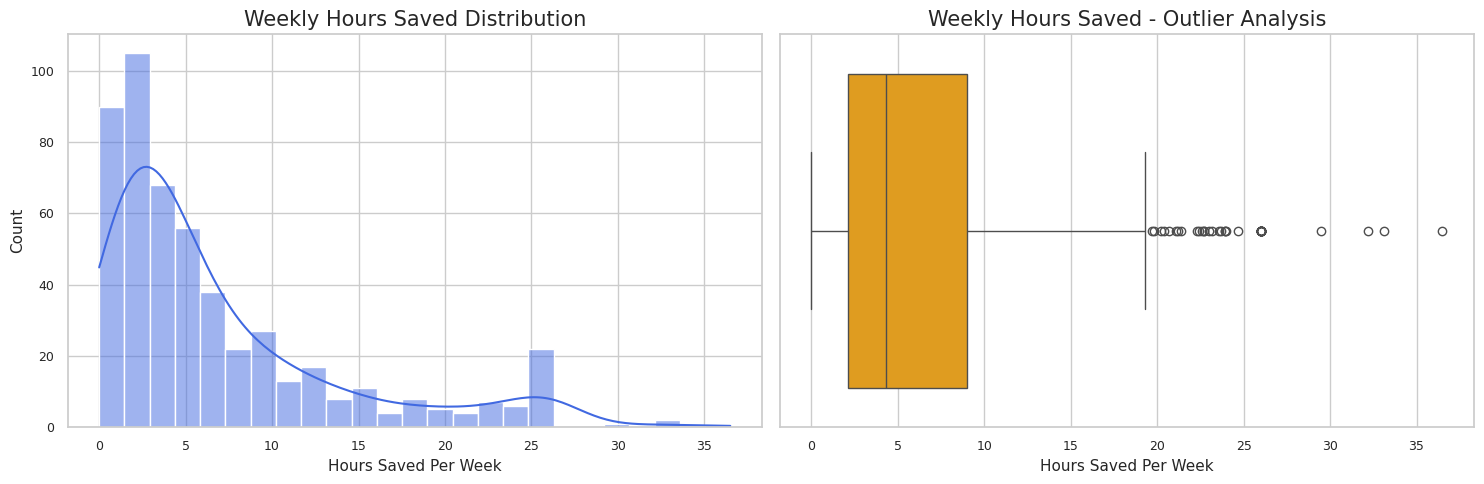

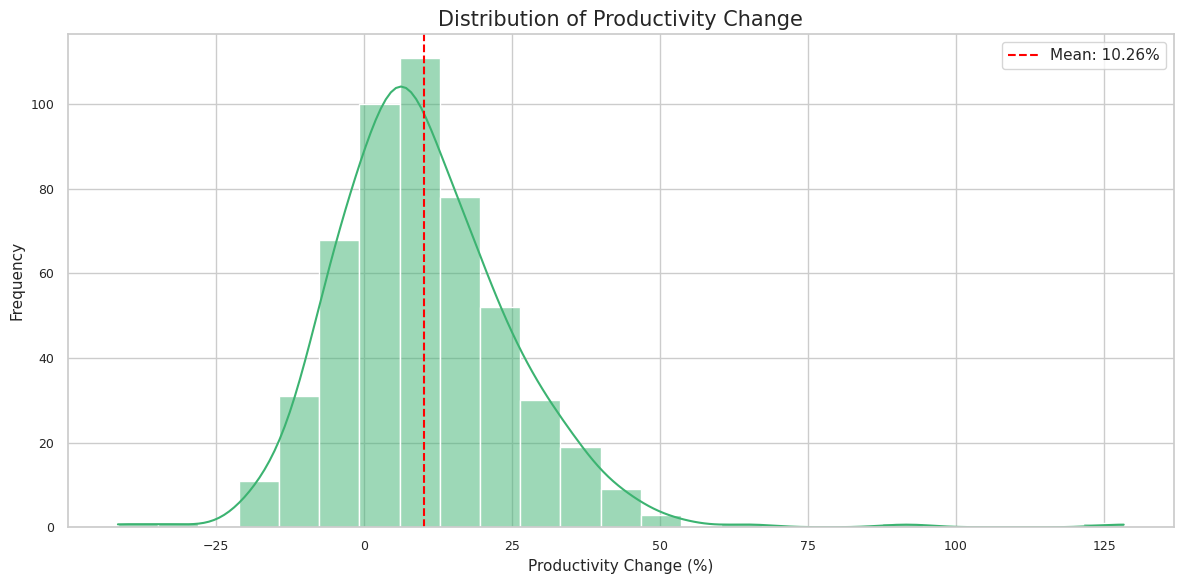

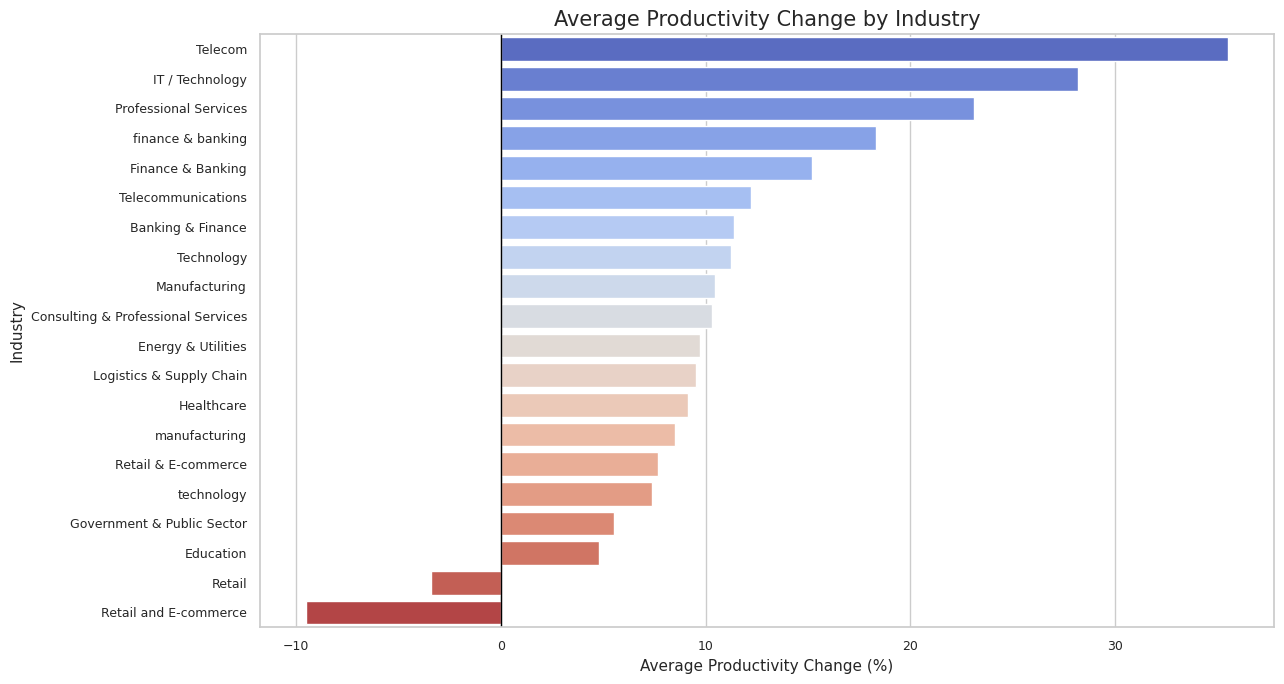

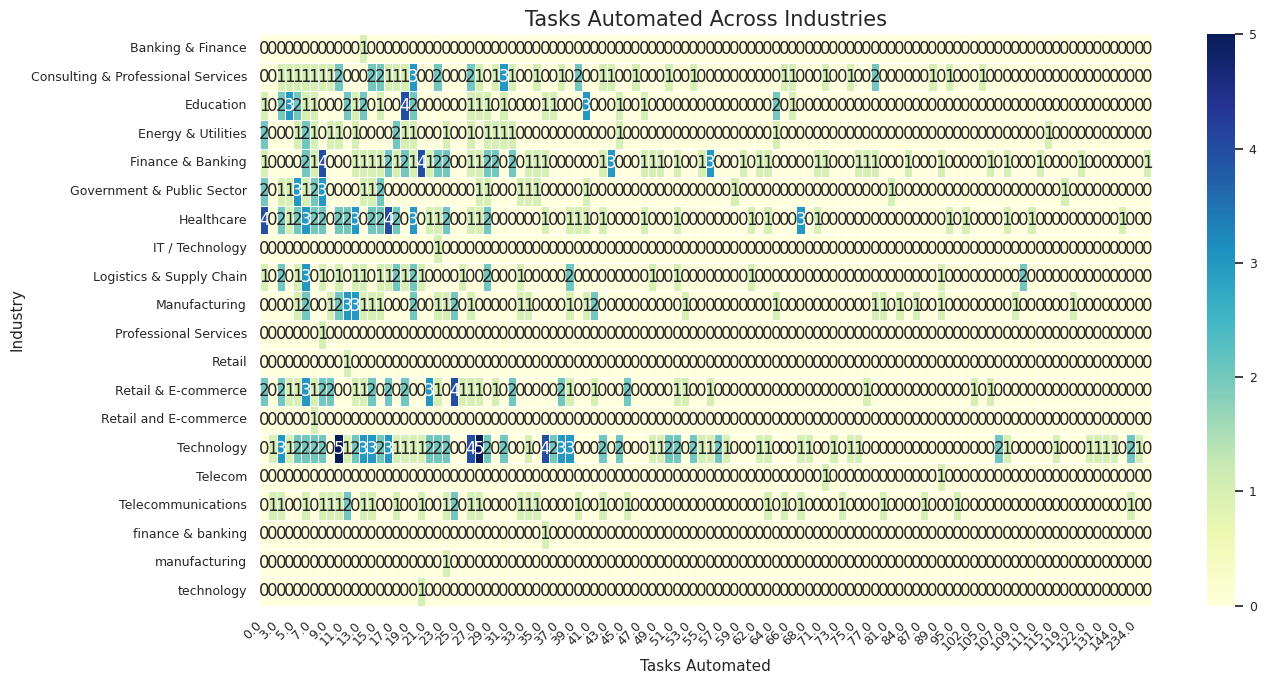

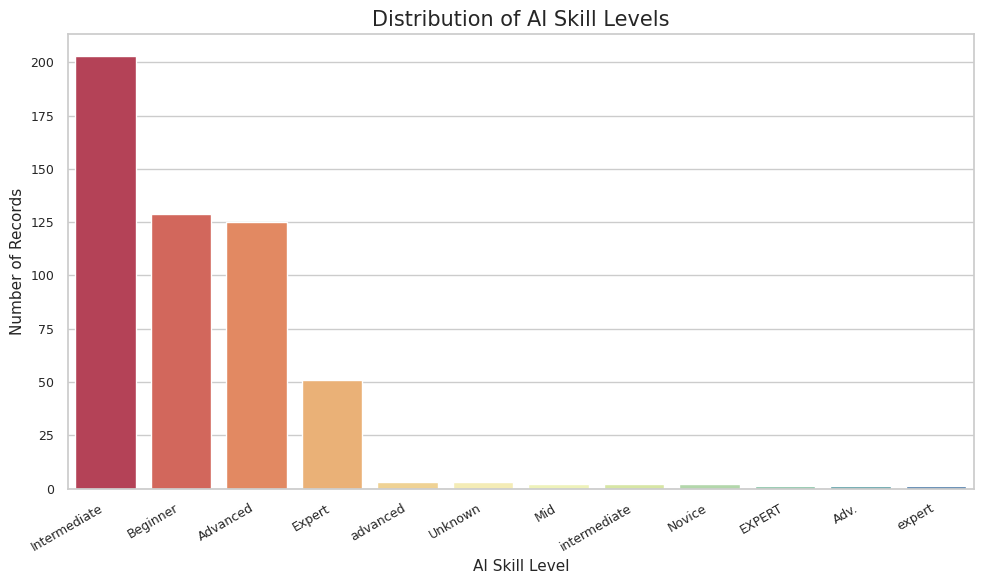

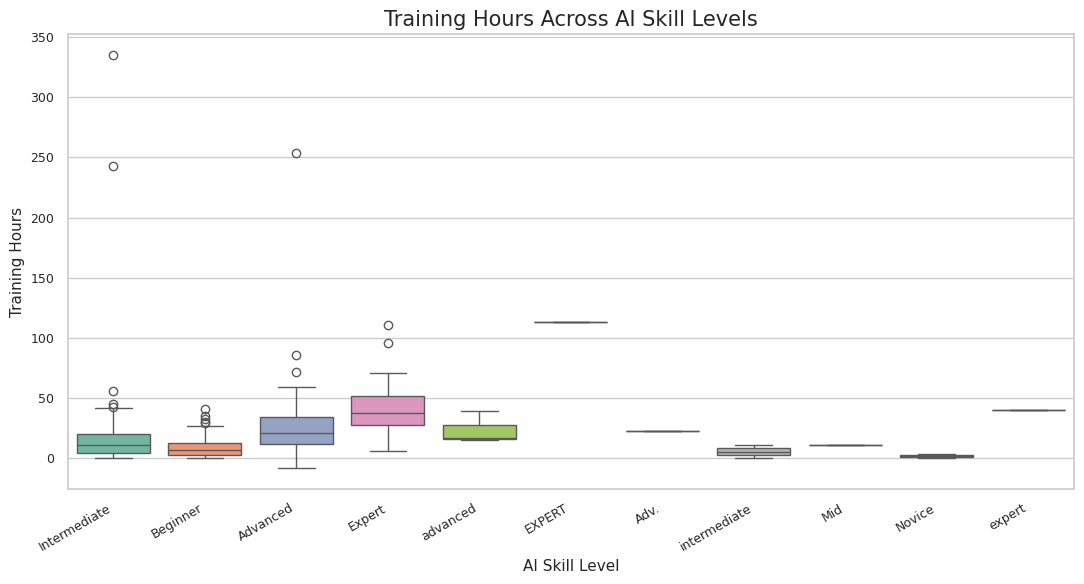

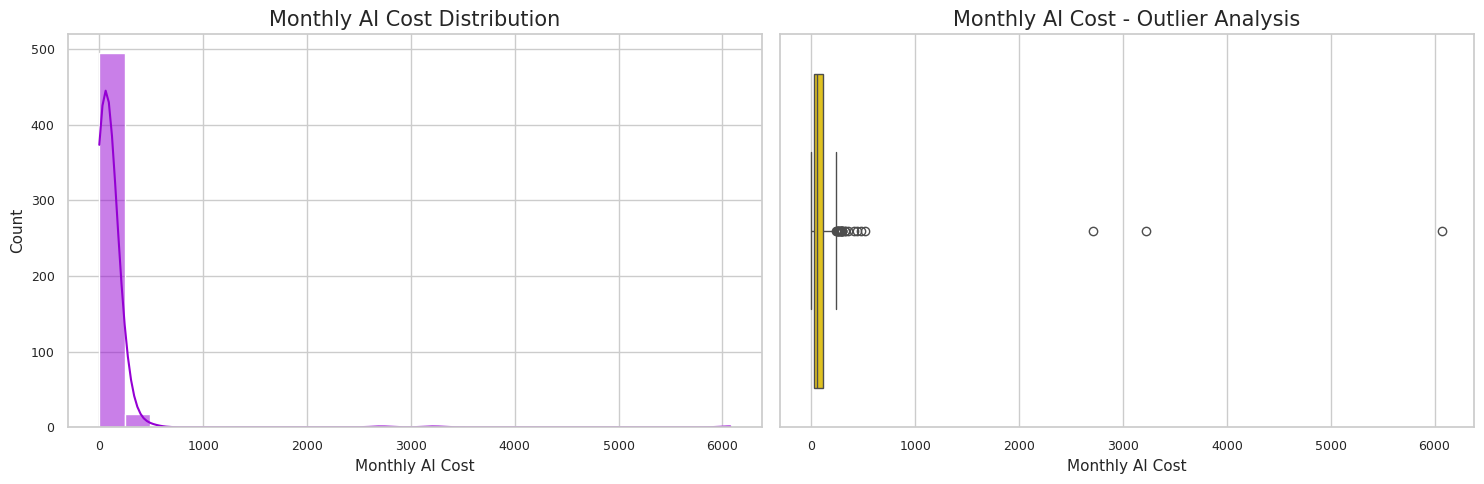

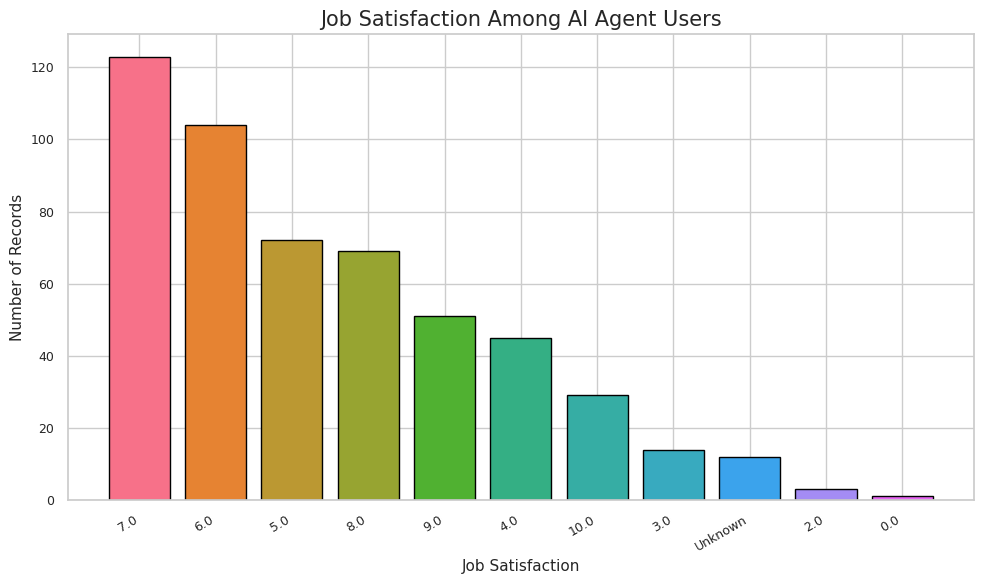

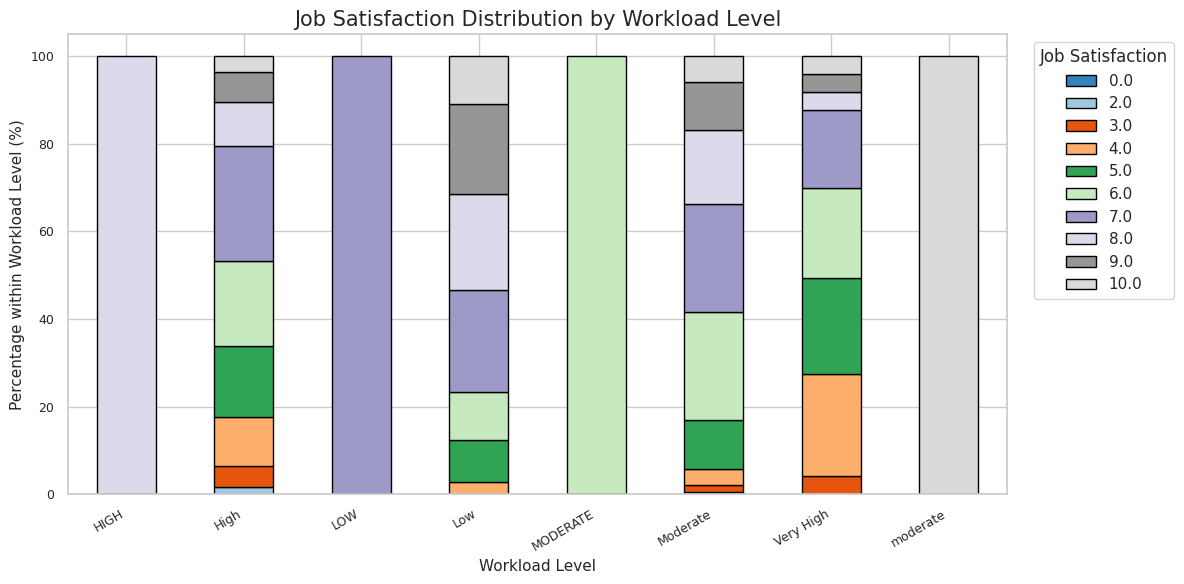

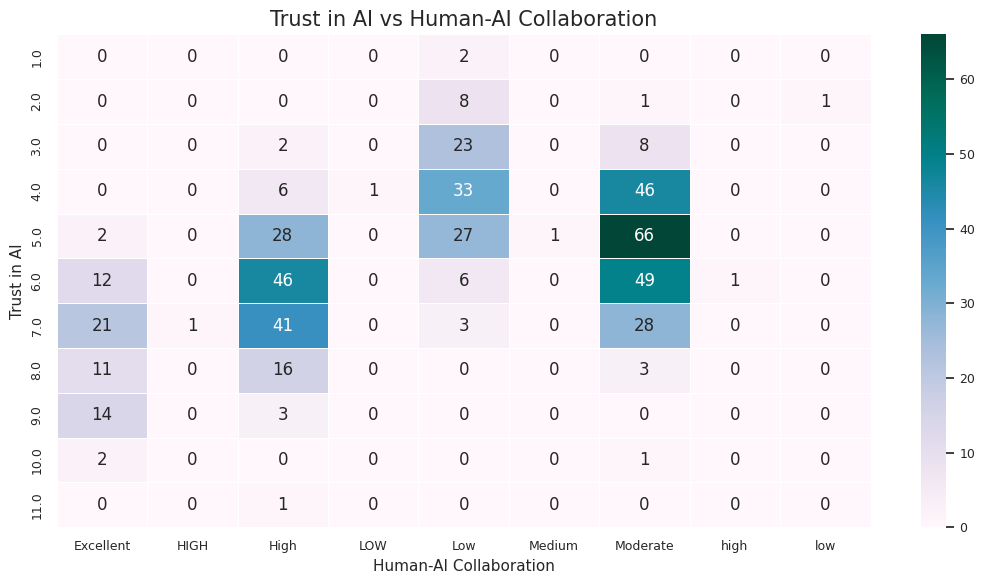

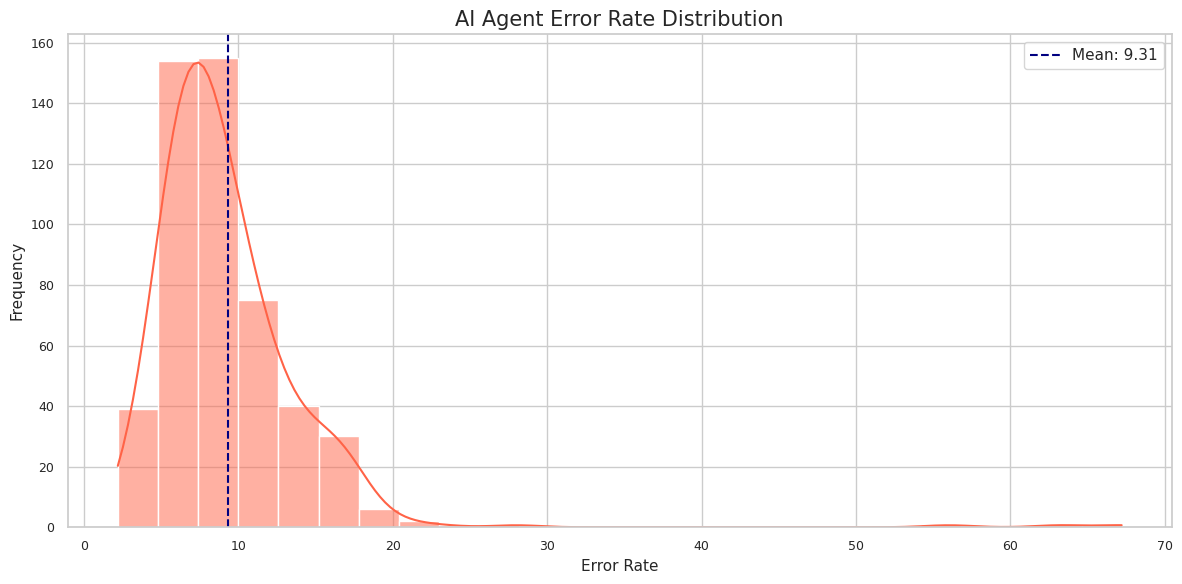

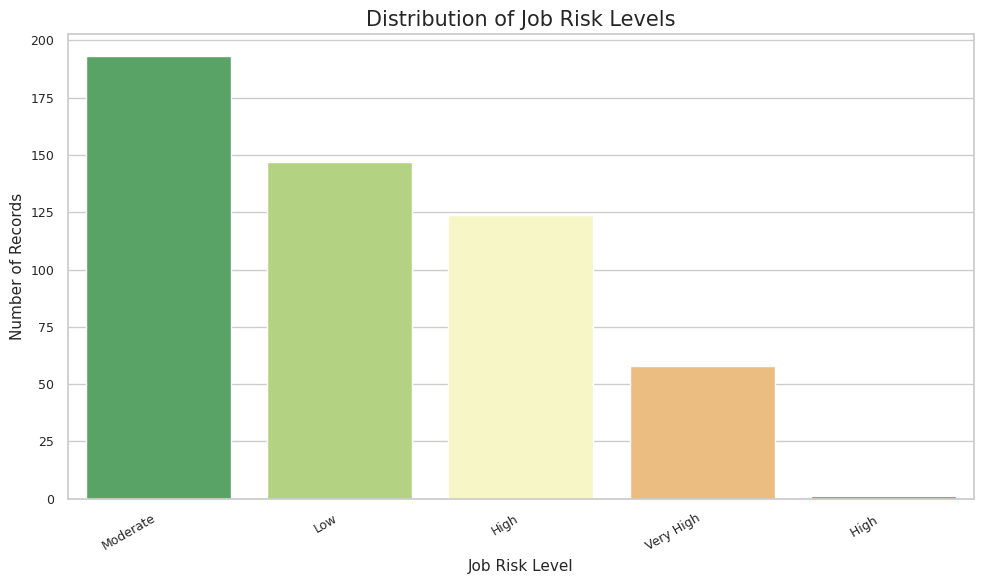

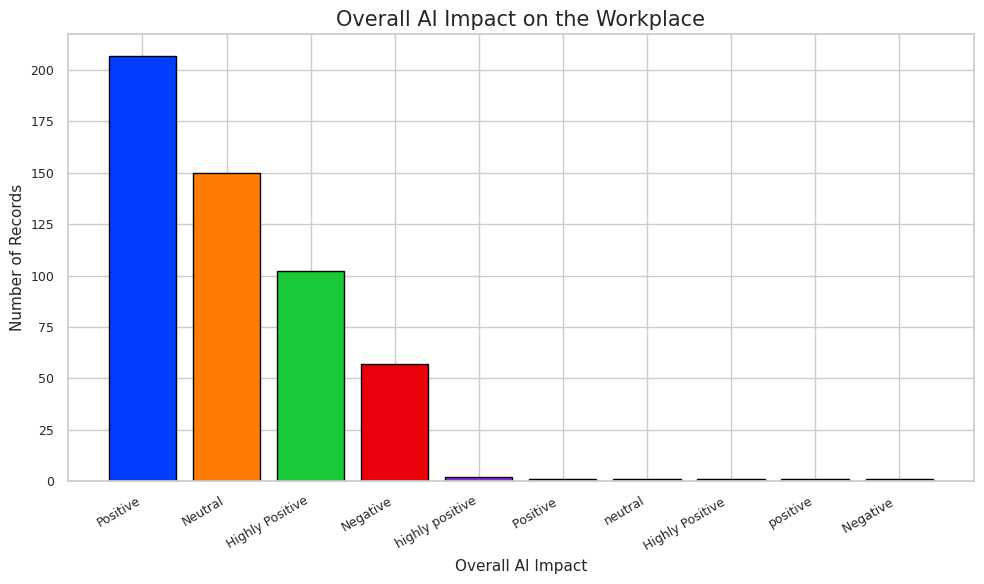

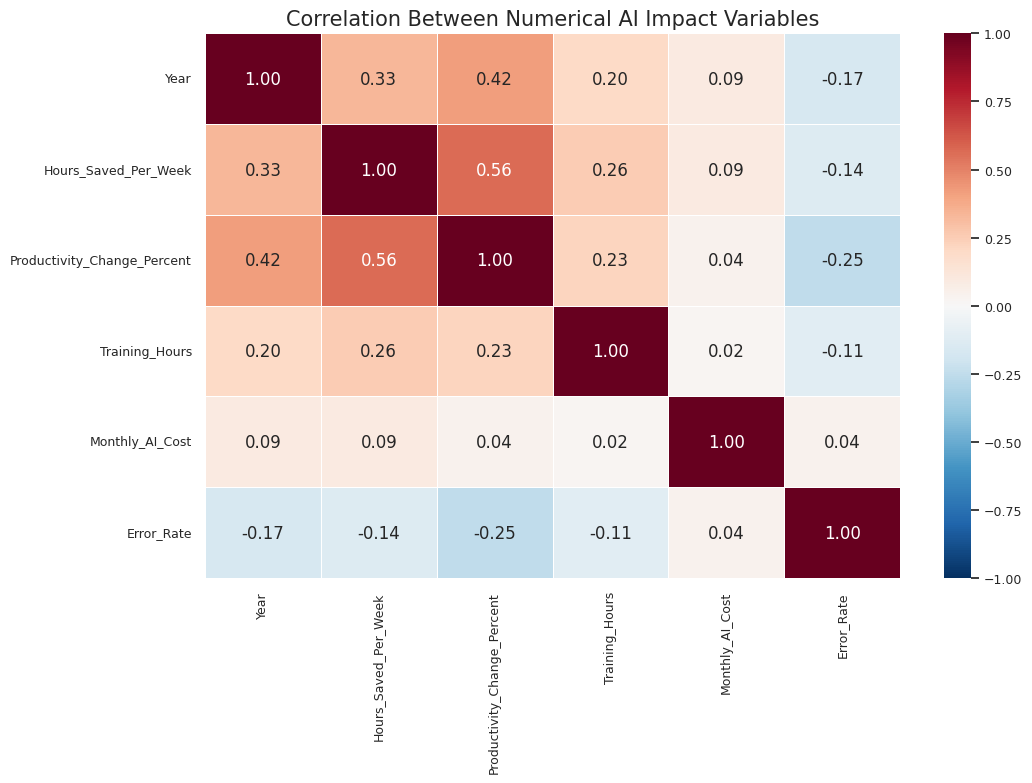

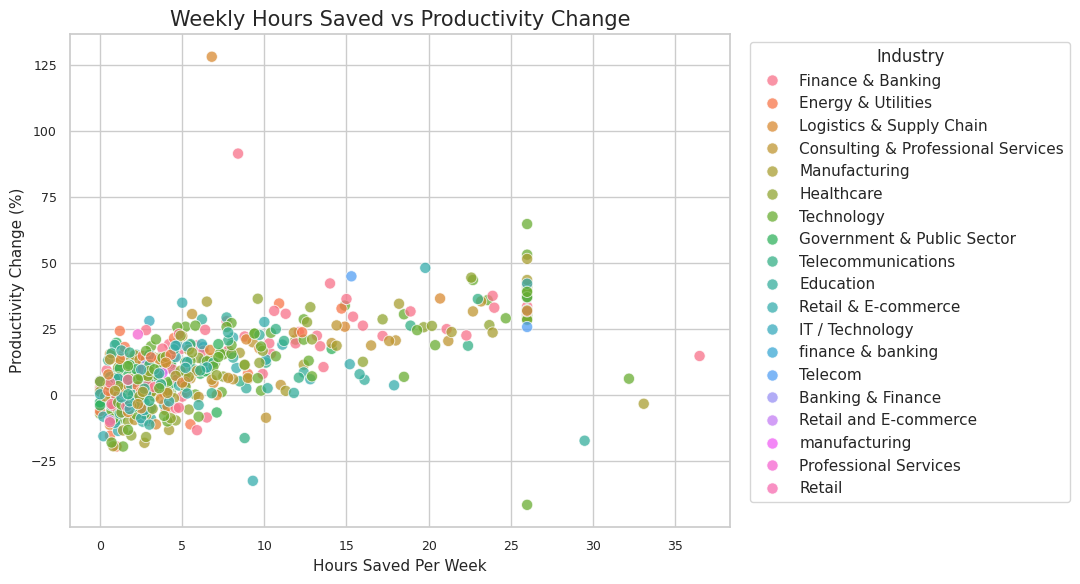

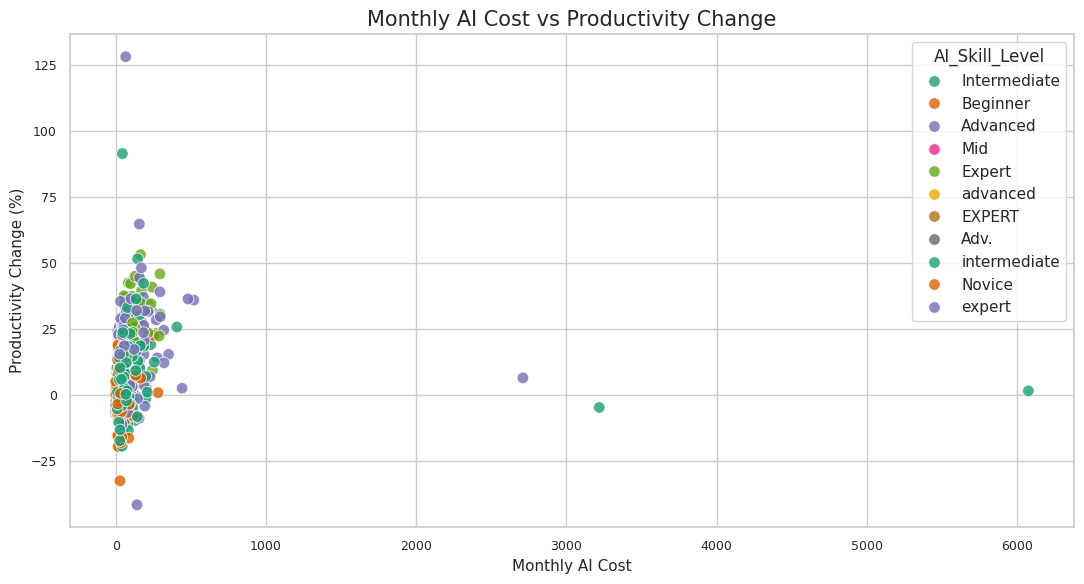

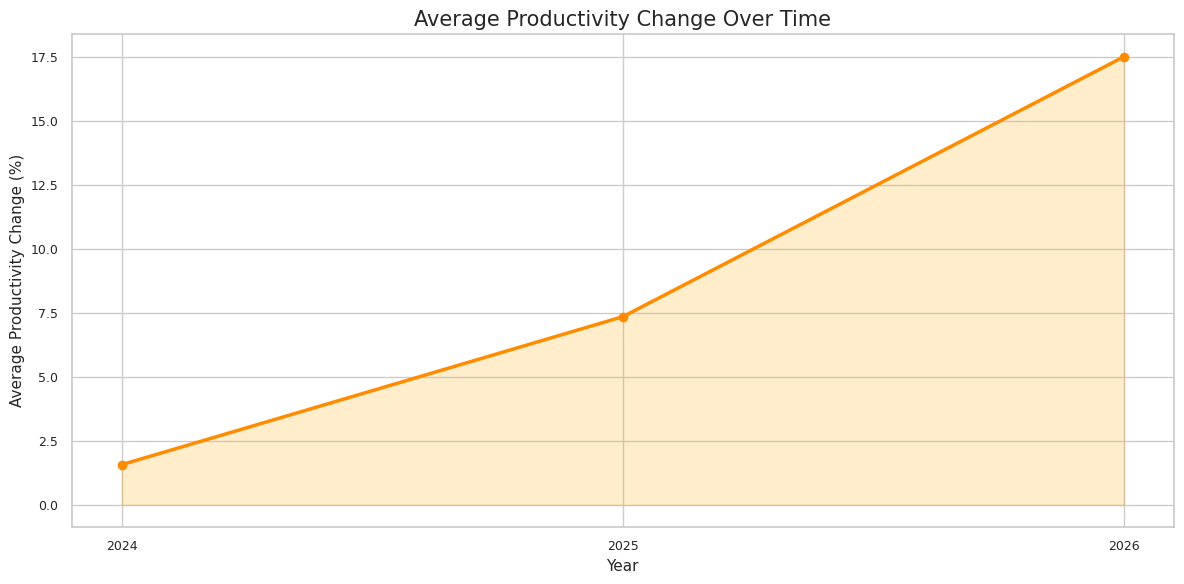

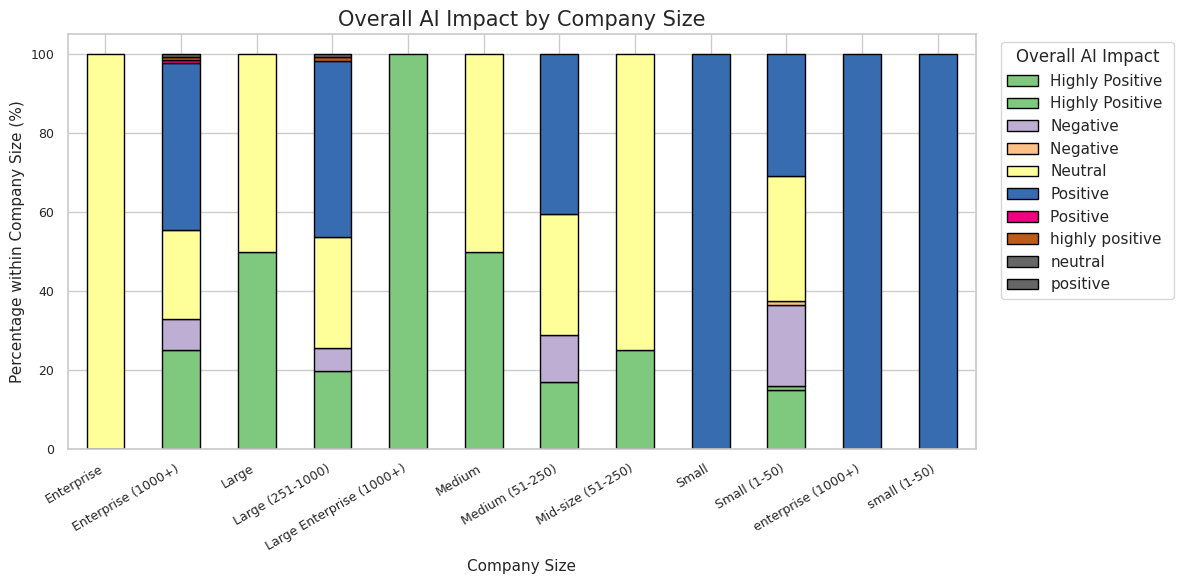


========== NUMERICAL SUMMARY ==========


,Hours_Saved_Per_Week,Productivity_Change_Percent,Training_Hours,Monthly_AI_Cost,Error_Rate
count,515.00,517.00,508.00,517.00,505.00
mean,6.88,10.26,19.04,102.85,9.31
std,7.12,15.33,26.12,327.18,5.51
min,0.00,-41.50,-8.00,0.00,2.20
25%,2.10,0.80,6.00,28.25,6.40
50%,4.30,8.10,13.00,57.72,8.20
75%,9.00,18.80,25.00,111.07,10.90
max,36.50,128.30,335.00,6075.96,67.20



========== AI IMPACT CATEGORY SUMMARY ==========

AI_Agent_Usage:
AI_Agent_Usage
Moderate     174
High         160
Low           88
Very High     80
No Usage      13
LOW            2
VERY HIGH      2
low            1
high           1
HIGH           1
moderate       1
Name: count, dtype: int64

AI_Agent_Type:
AI_Agent_Type
Multi-Agent System            97
Content Generation Agent      84
Research & Analysis Agent     71
Coding Agent                  60
Workflow Automation Agent     59
Data Processing Agent         52
Customer Service Agent        41
Scheduling & Admin Agent      39
No Agent                      13
customer service agent         2
WORKFLOW AUTOMATION AGENT      1
 Coding Agent                  1
CUSTOMER SERVICE AGENT         1
Research & Analysis Agent      1
 Scheduling & Admin Agent      1
Name: count, dtype: int64

Job_Satisfaction:
Job_Satisfaction
7.0     123
6.0     104
5.0      72
8.0      69
9.0      51
4.0      45
10.0     29
3.0      14
NaN      12
2.0       

In [13]:
# ============================================================
# AI AGENT USAGE & WORKPLACE IMPACT - DATA VISUALIZATION
# Works with an existing Pandas DataFrame named df
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. VISUALIZATION SETTINGS
# ------------------------------------------------------------

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9

# Different color palettes for different charts
palette1 = sns.color_palette("viridis", 12)
palette2 = sns.color_palette("Set2", 12)
palette3 = sns.color_palette("husl", 12)

# ------------------------------------------------------------
# 2. DATA PREPROCESSING
# ------------------------------------------------------------

df = df.copy()

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# Remove duplicate records
df = df.drop_duplicates()

# Convert numerical columns to numeric values
numeric_cols = [
    "Year",
    "Hours_Saved_Per_Week",
    "Productivity_Change_Percent",
    "Training_Hours",
    "Monthly_AI_Cost",
    "Error_Rate"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove missing values from the dataset only where necessary
print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nData Types:\n", df.dtypes)

# ------------------------------------------------------------
# 3. RECORDS BY YEAR
# ------------------------------------------------------------

if "Year" in df.columns:
    yearly_data = df["Year"].value_counts().sort_index()

    plt.figure(figsize=(12, 5))
    plt.bar(
        yearly_data.index.astype(str),
        yearly_data.values,
        color=palette1[:len(yearly_data)],
        edgecolor="black"
    )
    plt.title("Number of AI Agent Records by Year")
    plt.xlabel("Year")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 4. AI AGENT USAGE BY INDUSTRY
# ------------------------------------------------------------

if {"Industry", "AI_Agent_Usage"}.issubset(df.columns):
    industry_usage = pd.crosstab(
        df["Industry"], df["AI_Agent_Usage"]
    )

    industry_usage.plot(
        kind="bar",
        stacked=True,
        figsize=(14, 6),
        colormap="Set3",
        edgecolor="black"
    )

    plt.title("AI Agent Usage Across Industries")
    plt.xlabel("Industry")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="AI Agent Usage", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. AI AGENT TYPE DISTRIBUTION
# ------------------------------------------------------------

if "AI_Agent_Type" in df.columns:
    counts = df["AI_Agent_Type"].fillna("Unknown").value_counts()

    plt.figure(figsize=(10, 7))
    plt.pie(
        counts.values,
        labels=counts.index,
        autopct="%1.1f%%",
        startangle=140,
        colors=sns.color_palette("pastel", len(counts)),
        wedgeprops={"edgecolor": "white", "linewidth": 1.5}
    )
    plt.title("Distribution of AI Agent Types")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. JOB ROLE DISTRIBUTION
# ------------------------------------------------------------

if "Job_Role" in df.columns:
    role_counts = df["Job_Role"].fillna("Unknown").value_counts().head(15)

    plt.figure(figsize=(12, 7))
    sns.barplot(
        x=role_counts.values,
        y=role_counts.index,
        hue=role_counts.index,
        palette="magma",
        legend=False
    )
    plt.title("Top Job Roles Using AI Agents")
    plt.xlabel("Number of Records")
    plt.ylabel("Job Role")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 7. HOURS SAVED PER WEEK DISTRIBUTION
# ------------------------------------------------------------

if "Hours_Saved_Per_Week" in df.columns:
    values = df["Hours_Saved_Per_Week"].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.histplot(
        values, bins=25, kde=True,
        color="royalblue", ax=axes[0]
    )
    axes[0].set_title("Weekly Hours Saved Distribution")
    axes[0].set_xlabel("Hours Saved Per Week")

    sns.boxplot(
        x=values, color="orange", ax=axes[1]
    )
    axes[1].set_title("Weekly Hours Saved - Outlier Analysis")
    axes[1].set_xlabel("Hours Saved Per Week")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 8. PRODUCTIVITY CHANGE DISTRIBUTION
# ------------------------------------------------------------

if "Productivity_Change_Percent" in df.columns:
    values = df["Productivity_Change_Percent"].dropna()

    plt.figure(figsize=(12, 6))
    sns.histplot(
        values,
        bins=25,
        kde=True,
        color="mediumseagreen"
    )
    plt.axvline(
        values.mean(),
        color="red",
        linestyle="--",
        label=f"Mean: {values.mean():.2f}%"
    )
    plt.title("Distribution of Productivity Change")
    plt.xlabel("Productivity Change (%)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 9. PRODUCTIVITY CHANGE BY INDUSTRY
# ------------------------------------------------------------

if {"Industry", "Productivity_Change_Percent"}.issubset(df.columns):
    plot_data = df.dropna(
        subset=["Industry", "Productivity_Change_Percent"]
    )

    industry_productivity = (
        plot_data.groupby("Industry")["Productivity_Change_Percent"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(13, 7))
    sns.barplot(
        x=industry_productivity.values,
        y=industry_productivity.index,
        hue=industry_productivity.index,
        palette="coolwarm",
        legend=False
    )
    plt.axvline(0, color="black", linewidth=1)
    plt.title("Average Productivity Change by Industry")
    plt.xlabel("Average Productivity Change (%)")
    plt.ylabel("Industry")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 10. TASKS AUTOMATED BY INDUSTRY
# ------------------------------------------------------------

if {"Industry", "Tasks_Automated"}.issubset(df.columns):
    task_counts = pd.crosstab(
        df["Industry"], df["Tasks_Automated"]
    )

    plt.figure(figsize=(14, 7))
    sns.heatmap(
        task_counts,
        annot=True,
        fmt="g",
        cmap="YlGnBu",
        linewidths=0.5
    )
    plt.title("Tasks Automated Across Industries")
    plt.xlabel("Tasks Automated")
    plt.ylabel("Industry")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 11. AI SKILL LEVEL DISTRIBUTION
# ------------------------------------------------------------

if "AI_Skill_Level" in df.columns:
    skill_counts = df["AI_Skill_Level"].fillna("Unknown").value_counts()

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=skill_counts.index,
        y=skill_counts.values,
        hue=skill_counts.index,
        palette="Spectral",
        legend=False
    )
    plt.title("Distribution of AI Skill Levels")
    plt.xlabel("AI Skill Level")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 12. TRAINING HOURS BY AI SKILL LEVEL
# ------------------------------------------------------------

if {"AI_Skill_Level", "Training_Hours"}.issubset(df.columns):
    plot_data = df.dropna(subset=["AI_Skill_Level", "Training_Hours"])

    plt.figure(figsize=(11, 6))
    sns.boxplot(
        data=plot_data,
        x="AI_Skill_Level",
        y="Training_Hours",
        hue="AI_Skill_Level",
        palette="Set2",
        legend=False
    )
    plt.title("Training Hours Across AI Skill Levels")
    plt.xlabel("AI Skill Level")
    plt.ylabel("Training Hours")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 13. MONTHLY AI COST DISTRIBUTION
# ------------------------------------------------------------

if "Monthly_AI_Cost" in df.columns:
    values = df["Monthly_AI_Cost"].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.histplot(
        values, bins=25, kde=True,
        color="darkviolet", ax=axes[0]
    )
    axes[0].set_title("Monthly AI Cost Distribution")
    axes[0].set_xlabel("Monthly AI Cost")

    sns.boxplot(
        x=values, color="gold", ax=axes[1]
    )
    axes[1].set_title("Monthly AI Cost - Outlier Analysis")
    axes[1].set_xlabel("Monthly AI Cost")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 14. JOB SATISFACTION DISTRIBUTION
# ------------------------------------------------------------

if "Job_Satisfaction" in df.columns:
    satisfaction = (
        df["Job_Satisfaction"].fillna("Unknown").value_counts()
    )

    plt.figure(figsize=(10, 6))
    plt.bar(
        satisfaction.index.astype(str),
        satisfaction.values,
        color=palette3[:len(satisfaction)],
        edgecolor="black"
    )
    plt.title("Job Satisfaction Among AI Agent Users")
    plt.xlabel("Job Satisfaction")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 15. WORKLOAD LEVEL VS JOB SATISFACTION
# ------------------------------------------------------------

if {"Workload_Level", "Job_Satisfaction"}.issubset(df.columns):
    workload_satisfaction = pd.crosstab(
        df["Workload_Level"],
        df["Job_Satisfaction"],
        normalize="index"
    ) * 100

    workload_satisfaction.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6),
        colormap="tab20c",
        edgecolor="black"
    )
    plt.title("Job Satisfaction Distribution by Workload Level")
    plt.xlabel("Workload Level")
    plt.ylabel("Percentage within Workload Level (%)")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Job Satisfaction", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 16. TRUST IN AI VS HUMAN-AI COLLABORATION
# ------------------------------------------------------------

if {"Trust_in_AI", "Human_AI_Collaboration"}.issubset(df.columns):
    trust_collaboration = pd.crosstab(
        df["Trust_in_AI"],
        df["Human_AI_Collaboration"]
    )

    plt.figure(figsize=(11, 6))
    sns.heatmap(
        trust_collaboration,
        annot=True,
        fmt="g",
        cmap="PuBuGn",
        linewidths=0.5
    )
    plt.title("Trust in AI vs Human-AI Collaboration")
    plt.xlabel("Human-AI Collaboration")
    plt.ylabel("Trust in AI")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 17. ERROR RATE DISTRIBUTION
# ------------------------------------------------------------

if "Error_Rate" in df.columns:
    values = df["Error_Rate"].dropna()

    plt.figure(figsize=(12, 6))
    sns.histplot(
        values, bins=25, kde=True,
        color="tomato"
    )
    plt.axvline(
        values.mean(),
        color="navy",
        linestyle="--",
        label=f"Mean: {values.mean():.2f}"
    )
    plt.title("AI Agent Error Rate Distribution")
    plt.xlabel("Error Rate")
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 18. JOB RISK LEVEL DISTRIBUTION
# ------------------------------------------------------------

if "Job_Risk_Level" in df.columns:
    risk_counts = df["Job_Risk_Level"].fillna("Unknown").value_counts()

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=risk_counts.index,
        y=risk_counts.values,
        hue=risk_counts.index,
        palette="RdYlGn_r",
        legend=False
    )
    plt.title("Distribution of Job Risk Levels")
    plt.xlabel("Job Risk Level")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 19. OVERALL AI IMPACT
# ------------------------------------------------------------

if "Overall_AI_Impact" in df.columns:
    impact_counts = df["Overall_AI_Impact"].fillna("Unknown").value_counts()

    plt.figure(figsize=(10, 6))
    plt.bar(
        impact_counts.index.astype(str),
        impact_counts.values,
        color=sns.color_palette("bright", len(impact_counts)),
        edgecolor="black"
    )
    plt.title("Overall AI Impact on the Workplace")
    plt.xlabel("Overall AI Impact")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 20. NUMERICAL CORRELATION HEATMAP
# ------------------------------------------------------------

corr_cols = [
    col for col in numeric_cols
    if col in df.columns and df[col].notna().sum() > 1
]

if len(corr_cols) >= 2:
    corr_matrix = df[corr_cols].corr()

    plt.figure(figsize=(11, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        fmt=".2f",
        linewidths=0.5
    )
    plt.title("Correlation Between Numerical AI Impact Variables")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 21. HOURS SAVED VS PRODUCTIVITY CHANGE
# ------------------------------------------------------------

scatter_cols = [
    "Hours_Saved_Per_Week",
    "Productivity_Change_Percent"
]

if all(col in df.columns for col in scatter_cols):
    plot_data = df.dropna(subset=scatter_cols)

    plt.figure(figsize=(11, 6))
    sns.scatterplot(
        data=plot_data,
        x="Hours_Saved_Per_Week",
        y="Productivity_Change_Percent",
        hue="Industry" if "Industry" in df.columns else None,
        palette="husl",
        alpha=0.75,
        s=65
    )
    plt.title("Weekly Hours Saved vs Productivity Change")
    plt.xlabel("Hours Saved Per Week")
    plt.ylabel("Productivity Change (%)")

    if "Industry" in df.columns:
        plt.legend(
            title="Industry",
            bbox_to_anchor=(1.02, 1),
            loc="upper left"
        )

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 22. AI COST VS PRODUCTIVITY CHANGE
# ------------------------------------------------------------

if {"Monthly_AI_Cost", "Productivity_Change_Percent"}.issubset(df.columns):
    plot_data = df.dropna(
        subset=["Monthly_AI_Cost", "Productivity_Change_Percent"]
    )

    plt.figure(figsize=(11, 6))
    sns.scatterplot(
        data=plot_data,
        x="Monthly_AI_Cost",
        y="Productivity_Change_Percent",
        hue="AI_Skill_Level" if "AI_Skill_Level" in df.columns else None,
        palette="Dark2",
        alpha=0.8,
        s=70
    )
    plt.title("Monthly AI Cost vs Productivity Change")
    plt.xlabel("Monthly AI Cost")
    plt.ylabel("Productivity Change (%)")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 23. PRODUCTIVITY CHANGE BY YEAR
# ------------------------------------------------------------

if {"Year", "Productivity_Change_Percent"}.issubset(df.columns):
    yearly_productivity = (
        df.groupby("Year")["Productivity_Change_Percent"]
        .mean()
        .dropna()
        .sort_index()
    )

    plt.figure(figsize=(12, 6))
    plt.plot(
        yearly_productivity.index,
        yearly_productivity.values,
        marker="o",
        linewidth=2.5,
        color="darkorange"
    )
    plt.fill_between(
        yearly_productivity.index,
        yearly_productivity.values,
        alpha=0.2,
        color="orange"
    )
    plt.title("Average Productivity Change Over Time")
    plt.xlabel("Year")
    plt.ylabel("Average Productivity Change (%)")
    plt.xticks(yearly_productivity.index)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 24. AI IMPACT BY COMPANY SIZE
# ------------------------------------------------------------

if {"Company_Size", "Overall_AI_Impact"}.issubset(df.columns):
    impact_by_size = pd.crosstab(
        df["Company_Size"],
        df["Overall_AI_Impact"],
        normalize="index"
    ) * 100

    impact_by_size.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6),
        colormap="Accent",
        edgecolor="black"
    )
    plt.title("Overall AI Impact by Company Size")
    plt.xlabel("Company Size")
    plt.ylabel("Percentage within Company Size (%)")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Overall AI Impact", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 25. SUMMARY STATISTICS
# ------------------------------------------------------------

summary_cols = [
    "Hours_Saved_Per_Week",
    "Productivity_Change_Percent",
    "Training_Hours",
    "Monthly_AI_Cost",
    "Error_Rate"
]

available_cols = [col for col in summary_cols if col in df.columns]

if available_cols:
    print("\n========== NUMERICAL SUMMARY ==========")
    display(df[available_cols].describe().round(2))

print("\n========== AI IMPACT CATEGORY SUMMARY ==========")

for col in [
    "AI_Agent_Usage",
    "AI_Agent_Type",
    "Job_Satisfaction",
    "Trust_in_AI",
    "Job_Risk_Level",
    "Overall_AI_Impact"
]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False))

print("\nAll available visualizations completed successfully!")


## Feature engineering

Removing classes with fewer than 2 records: ['neutral', 'positive']
DATASET INFORMATION
Dataset shape: (523, 22)
Feature shape: (521, 20)
Target column: Overall_AI_Impact

Target class distribution:
Overall_AI_Impact
Positive           208
Neutral            150
Highly Positive    103
Negative            58
highly positive      2
Name: count, dtype: int64

Target Label Encoding:
Highly Positive -> 0
Negative -> 1
Neutral -> 2
Positive -> 3
highly positive -> 4

Numerical Features:
['Year', 'Tasks_Automated', 'Hours_Saved_Per_Week', 'Productivity_Change_Percent', 'Training_Hours', 'Monthly_AI_Cost', 'Job_Satisfaction', 'Trust_in_AI', 'Error_Rate']

Categorical Features:
['Country', 'Industry', 'Company_Size', 'Job_Role', 'Age_Group', 'AI_Agent_Usage', 'AI_Agent_Type', 'AI_Skill_Level', 'Workload_Level', 'Human_AI_Collaboration', 'Job_Risk_Level']

Training samples: 416
Testing samples: 105
Training percentage: 79.85 %
Testing percentage: 20.15 %

Preprocessing pipeline created successfu

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC (%)
0,Random Forest,58.10,61.90,58.10,57.14,79.12
1,Logistic Regression,56.19,58.60,56.19,57.05,78.29
2,Extra Trees,57.14,55.16,57.14,54.48,76.86
3,Histogram Gradient Boosting,51.43,51.37,51.43,50.69,77.52
4,Gradient Boosting,51.43,51.59,51.43,50.46,77.04
5,Decision Tree,49.52,50.92,49.52,49.76,63.51
6,Support Vector Machine,38.10,44.04,38.10,40.00,68.43
7,K-Nearest Neighbors,38.10,43.59,38.10,37.69,52.99


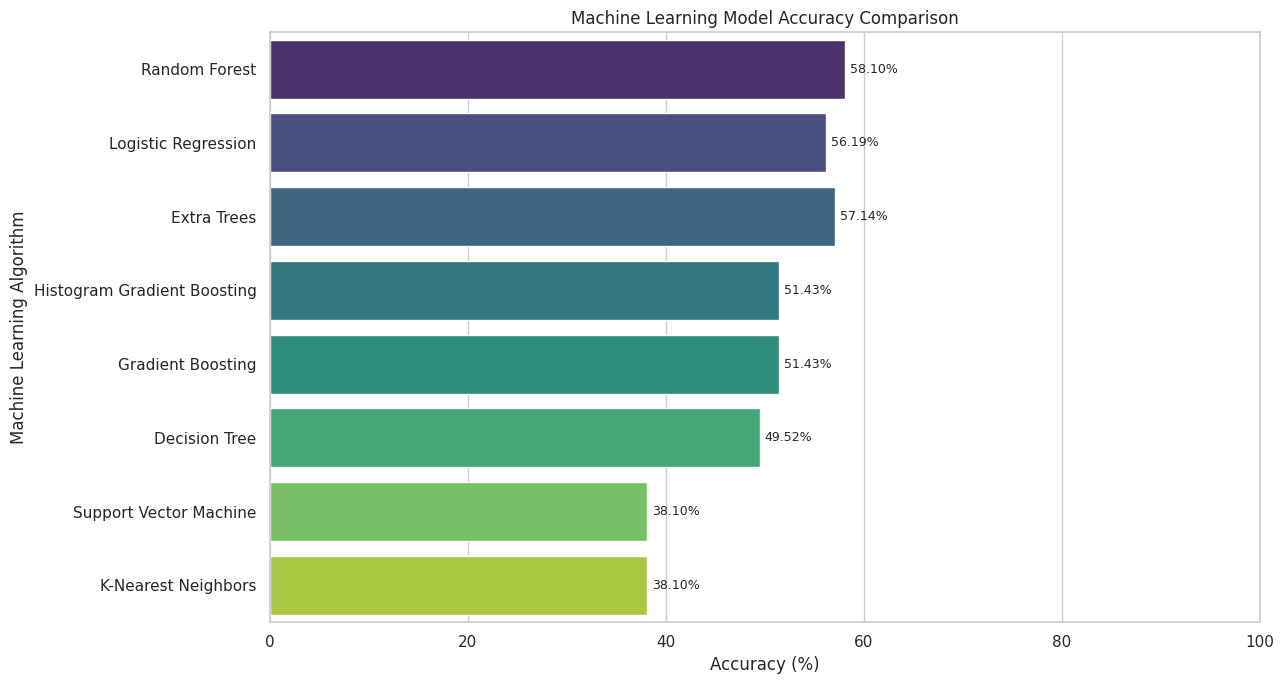

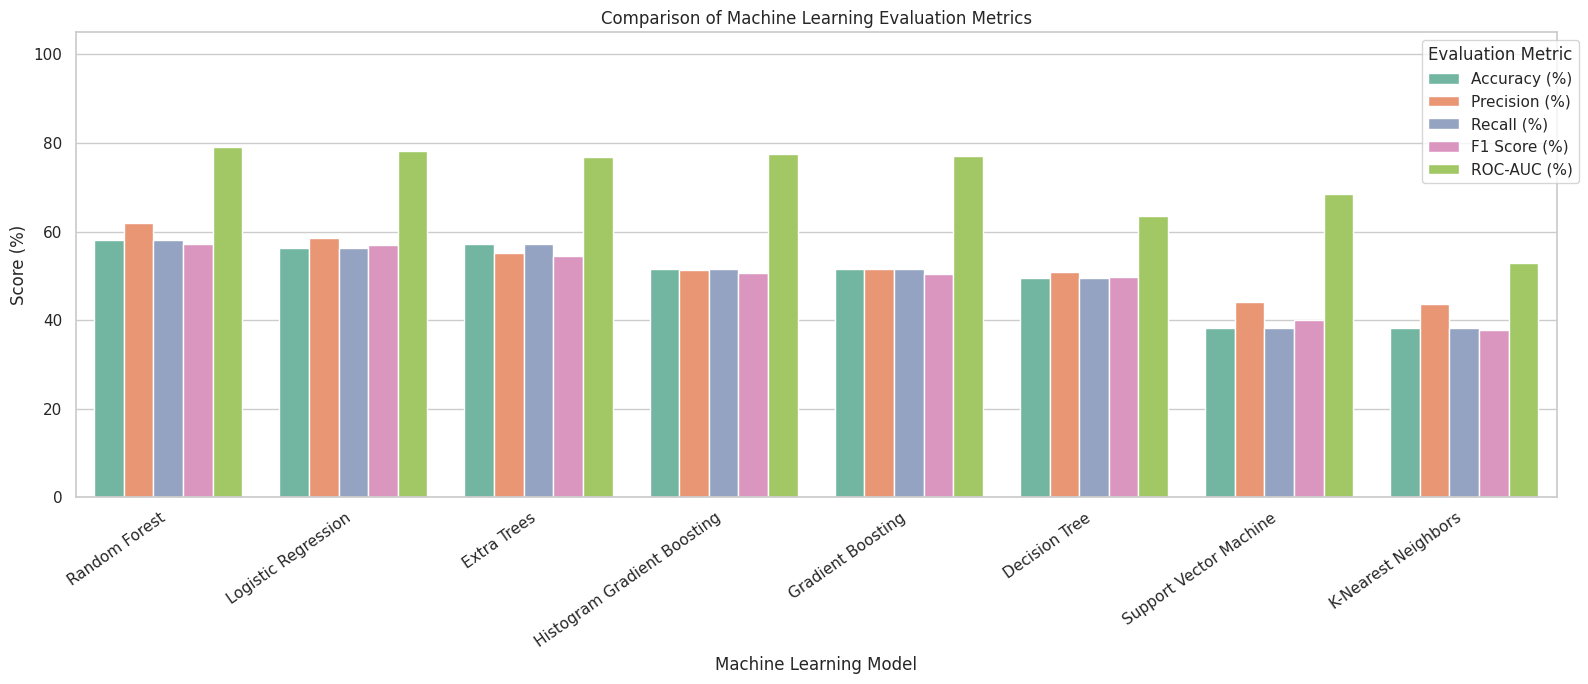


Best model based on weighted F1 score: Random Forest


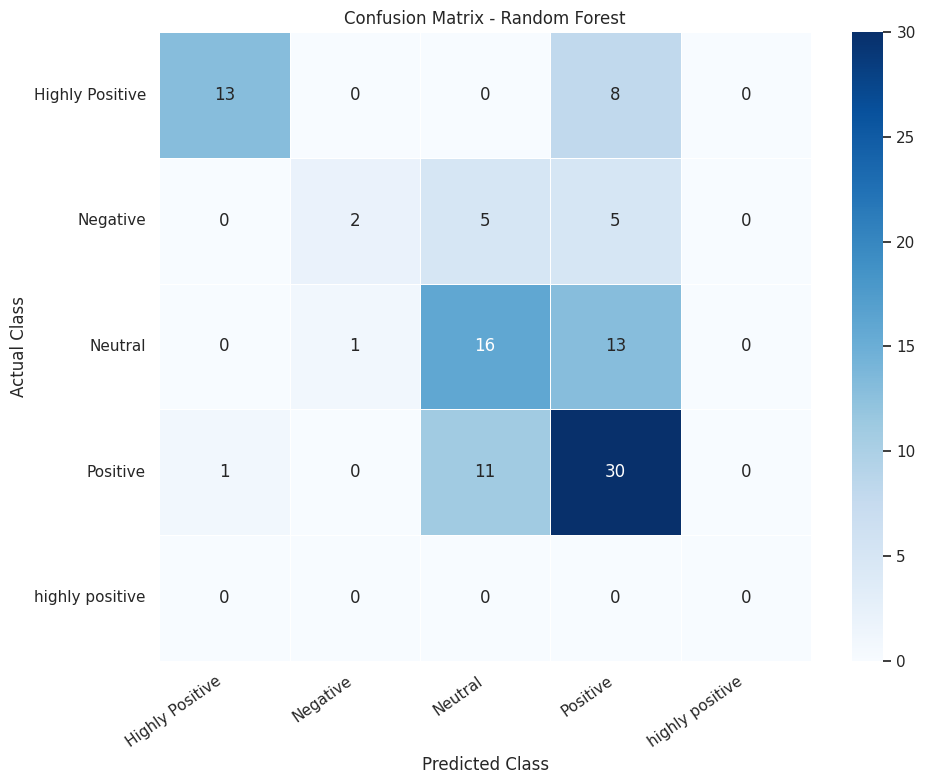

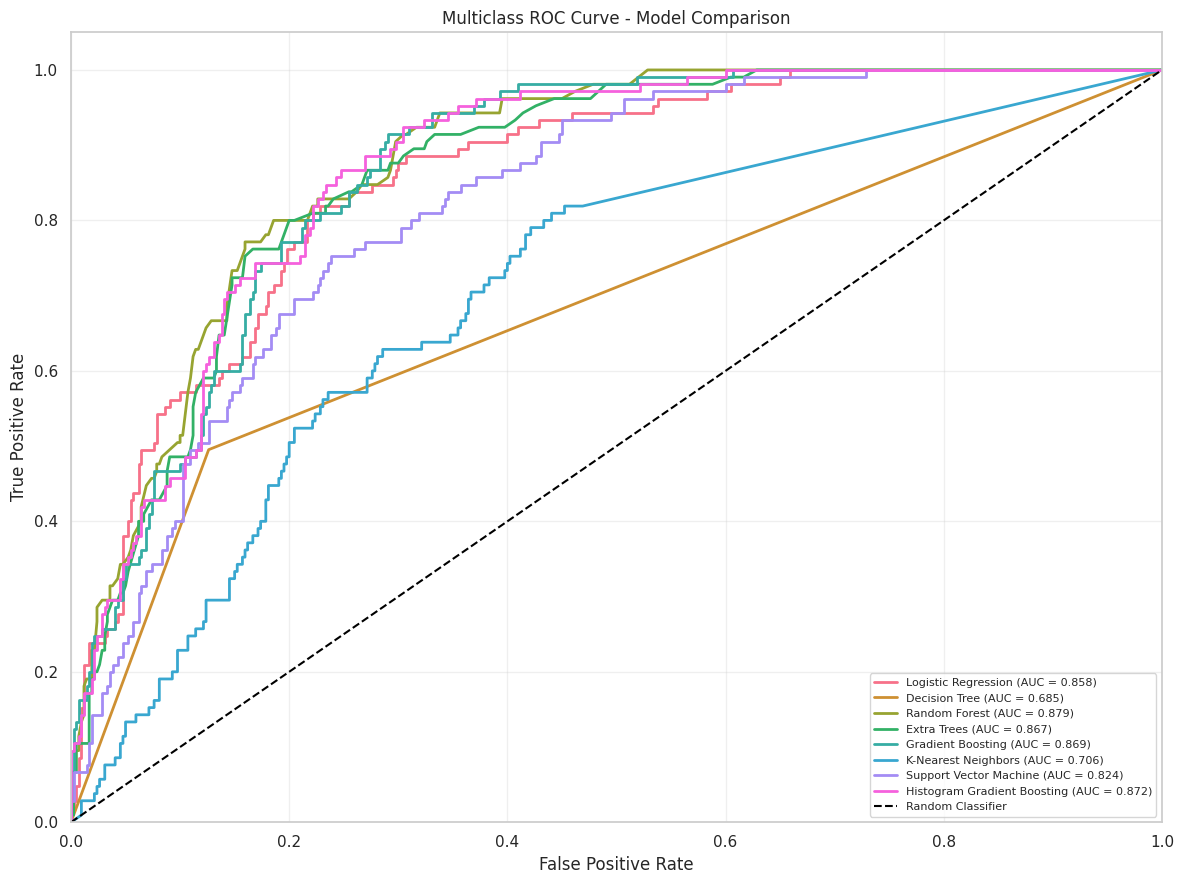

Skipping ROC for highly positive: test set contains only one class outcome.


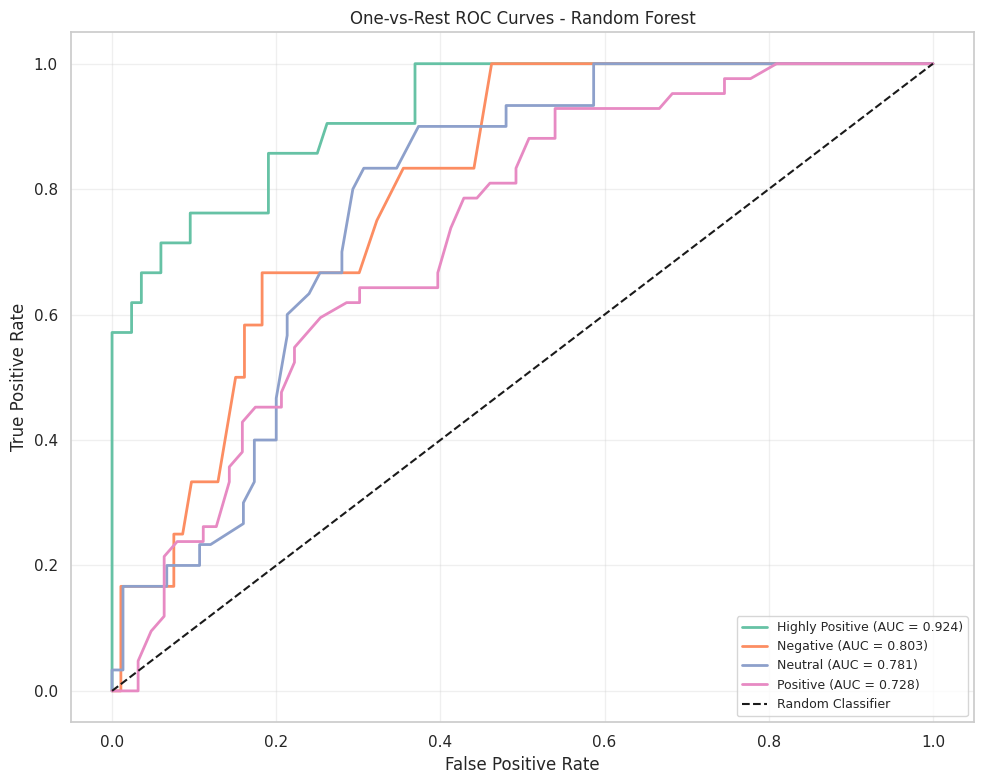


Individual Class ROC-AUC Scores:


,Class,AUC
0,Highly Positive,0.9243
1,Negative,0.8029
2,Neutral,0.7813
3,Positive,0.7283


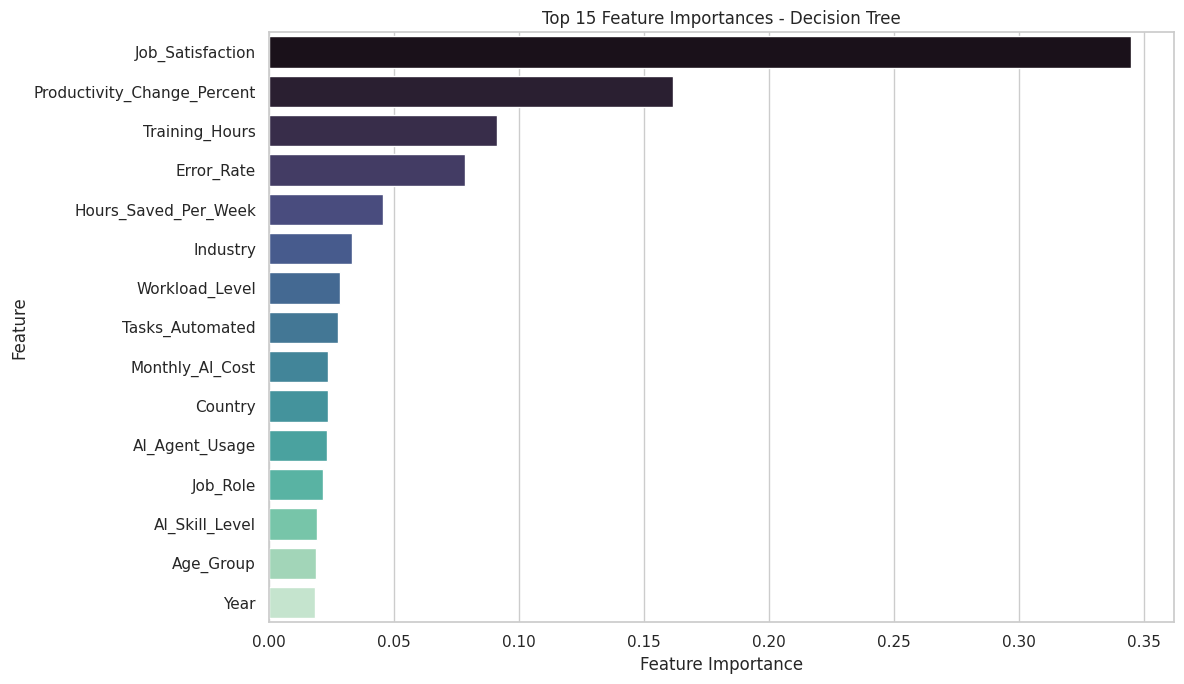


Top 15 Important Features:


,Feature,Importance
6,Job_Satisfaction,0.3447
3,Productivity_Change_Percent,0.1616
4,Training_Hours,0.0911
8,Error_Rate,0.0782
2,Hours_Saved_Per_Week,0.0457
10,Industry,0.0332
17,Workload_Level,0.0282
1,Tasks_Automated,0.0276
5,Monthly_AI_Cost,0.0235
9,Country,0.0234



FINAL MACHINE LEARNING SUMMARY
Target column: Overall_AI_Impact
Number of target classes: 5
Training records: 416
Testing records: 105
Models evaluated: 8
Best model: Random Forest
Accuracy (%): 58.10
Precision (%): 61.90
Recall (%): 58.10
F1 Score (%): 57.14
ROC-AUC (%): 79.12

Target categories:
['Highly Positive', 'Negative', 'Neutral', 'Positive', 'highly positive']

Machine learning workflow completed successfully!


In [14]:
# ================================================================
# AI AGENT USAGE & WORKPLACE IMPACT
# MACHINE LEARNING + TRAIN TEST SPLIT + LABEL ENCODING + ROC CURVE
# Target Column: Overall_AI_Impact
# ================================================================

# STEP 1: IMPORT LIBRARIES

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    LabelEncoder,
    OrdinalEncoder,
    StandardScaler,
    label_binarize
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

# ------------------------------------------------
# STEP 2: LOAD AND PREPARE DATA
# ------------------------------------------------
# If df is already loaded, no need to load the file again.

df_ml = df.copy()
df_ml.columns = df_ml.columns.str.strip()
df_ml = df_ml.drop_duplicates()

TARGET = "Overall_AI_Impact"

if TARGET not in df_ml.columns:
    raise ValueError(f"Target column '{TARGET}' is not present in df.")

# Remove rows without a known target
df_ml = df_ml.dropna(subset=[TARGET]).copy()

# Remove blank target labels
df_ml = df_ml[
    df_ml[TARGET].astype(str).str.strip().ne("")
].copy()

# Exclude ID columns to avoid using identifiers as predictors
drop_cols = [
    col for col in ["Record_ID"] if col in df_ml.columns
]

X = df_ml.drop(columns=[TARGET] + drop_cols)
y_original = df_ml[TARGET].astype(str).str.strip()

# Remove rows belonging to classes with fewer than 2 records
class_counts = y_original.value_counts()
rare_classes = class_counts[class_counts < 2].index

if len(rare_classes) > 0:
    print("Removing classes with fewer than 2 records:", list(rare_classes))
    valid_rows = ~y_original.isin(rare_classes)
    X = X.loc[valid_rows].copy()
    y_original = y_original.loc[valid_rows].copy()

if y_original.nunique() < 2:
    raise ValueError(
        "At least two target classes with sufficient records are required."
    )

print("=" * 65)
print("DATASET INFORMATION")
print("=" * 65)
print("Dataset shape:", df_ml.shape)
print("Feature shape:", X.shape)
print("Target column:", TARGET)
print("\nTarget class distribution:")
print(y_original.value_counts())

# ------------------------------------------------
# STEP 3: LABEL ENCODE THE TARGET
# ------------------------------------------------

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original)

class_names = label_encoder.classes_
n_classes = len(class_names)

print("\nTarget Label Encoding:")
for encoded_value, original_value in enumerate(class_names):
    print(f"{original_value} -> {encoded_value}")

# ------------------------------------------------
# STEP 4: IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

# ------------------------------------------------
# STEP 5: TRAIN-TEST SPLIT
# 80% TRAINING, 20% TESTING
# ------------------------------------------------

# Stratification preserves class proportions where possible.
# Reduce test size if necessary to ensure every class can be represented.

n_samples = len(y)
n_test = max(
    int(np.ceil(0.20 * n_samples)),
    n_classes
)

if n_test >= n_samples or (n_samples - n_test) < n_classes:
    raise ValueError(
        "Not enough records to create a stratified 80/20 split. "
        "Collect more samples for the target classes."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=n_test,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training percentage:", round(100 * len(y_train) / n_samples, 2), "%")
print("Testing percentage:", round(100 * len(y_test) / n_samples, 2), "%")

# ------------------------------------------------
# STEP 6: DATA PREPROCESSING
# ------------------------------------------------
# Numerical columns:
# - Fill missing values with median
# - Standardize features
#
# Categorical columns:
# - Fill missing values with most frequent category
# - Apply ordinal/label-style encoding
#
# The preprocessing is fitted ONLY on training data.

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("\nPreprocessing pipeline created successfully.")

# ------------------------------------------------
# STEP 7: DEFINE MACHINE LEARNING ALGORITHMS
# ------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ),

    "Support Vector Machine": SVC(
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        random_state=RANDOM_STATE
    )
}

# ------------------------------------------------
# STEP 8: TRAIN MODELS AND EVALUATE PERFORMANCE
# ------------------------------------------------

results = []
trained_models = {}
predictions = {}
probabilities = {}
failed_models = {}

for model_name, classifier in models.items():

    print("\n" + "=" * 65)
    print("TRAINING:", model_name)
    print("=" * 65)

    try:
        model_pipeline = Pipeline(steps=[
            ("preprocessing", preprocessor),
            ("classifier", classifier)
        ])

        model_pipeline.fit(X_train, y_train)

        # Predict target classes
        y_pred = model_pipeline.predict(X_test)

        # Predict class probabilities for ROC-AUC
        y_proba = model_pipeline.predict_proba(X_test)

        # Align probability columns to all encoded classes
        fitted_classifier = model_pipeline.named_steps["classifier"]
        fitted_classes = fitted_classifier.classes_

        aligned_proba = np.zeros((len(y_test), n_classes))
        for j, class_id in enumerate(fitted_classes):
            aligned_proba[:, int(class_id)] = y_proba[:, j]

        # Evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
        recall = recall_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )

        # ROC-AUC calculation
        if n_classes == 2:
            auc = roc_auc_score(
                y_test, aligned_proba[:, 1]
            )
        else:
            auc = roc_auc_score(
                y_test,
                aligned_proba,
                labels=np.arange(n_classes),
                multi_class="ovr",
                average="weighted"
            )

        results.append({
            "Model": model_name,
            "Accuracy (%)": accuracy * 100,
            "Precision (%)": precision * 100,
            "Recall (%)": recall * 100,
            "F1 Score (%)": f1 * 100,
            "ROC-AUC (%)": auc * 100
        })

        trained_models[model_name] = model_pipeline
        predictions[model_name] = y_pred
        probabilities[model_name] = aligned_proba

        print(f"Accuracy:  {accuracy * 100:.2f}%")
        print(f"Precision: {precision * 100:.2f}%")
        print(f"Recall:    {recall * 100:.2f}%")
        print(f"F1 Score:  {f1 * 100:.2f}%")
        print(f"ROC-AUC:   {auc * 100:.2f}%")

        print("\nClassification Report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(n_classes),
            target_names=class_names,
            zero_division=0
        ))

    except Exception as e:
        failed_models[model_name] = str(e)
        print("Model failed:", str(e))

if not results:
    raise RuntimeError(
        "All models failed. Review the printed error messages and dataset."
    )

# ------------------------------------------------
# STEP 9: MODEL COMPARISON TABLE
# ------------------------------------------------

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score (%)",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 80)

display(results_df.round(2))

if failed_models:
    print("\nModels that could not be evaluated:")
    for name, error in failed_models.items():
        print(f"{name}: {error}")

# ------------------------------------------------
# STEP 10: MODEL ACCURACY COMPARISON
# ------------------------------------------------

plt.figure(figsize=(13, 7))

sns.barplot(
    data=results_df,
    x="Accuracy (%)",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Accuracy (%)")
plt.ylabel("Machine Learning Algorithm")
plt.xlim(0, 100)

for i, value in enumerate(results_df["Accuracy (%)"]):
    plt.text(
        value + 0.5, i,
        f"{value:.2f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------
# STEP 11: COMPARE ALL EVALUATION METRICS
# ------------------------------------------------

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 Score (%)",
    "ROC-AUC (%)"
]

comparison_long = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(16, 7))

sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.title("Comparison of Machine Learning Evaluation Metrics")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ------------------------------------------------
# STEP 12: CONFUSION MATRIX FOR THE BEST MODEL
# ------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

print("\nBest model based on weighted F1 score:", best_model_name)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=np.arange(n_classes)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# STEP 13: MULTICLASS ROC CURVE
# ------------------------------------------------
# One-vs-Rest ROC curves:
# Each class is compared against all remaining classes.
#
# The micro-average ROC summarizes predictions across
# all classes and is useful for comparing multiclass models.

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(12, 9))

roc_colors = sns.color_palette(
    "husl", len(trained_models)
)

for (model_name, y_proba), color in zip(
    probabilities.items(), roc_colors
):

    try:
        # Micro-average ROC across all classes
        fpr, tpr, thresholds = roc_curve(
            y_test_binary.ravel(),
            y_proba.ravel()
        )

        micro_auc = roc_auc_score(
            y_test_binary,
            y_proba,
            average="micro"
        )

        plt.plot(
            fpr,
            tpr,
            color=color,
            linewidth=2,
            label=f"{model_name} (AUC = {micro_auc:.3f})"
        )

    except Exception as e:
        print(f"ROC curve skipped for {model_name}: {e}")

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Random Classifier"
)

plt.title("Multiclass ROC Curve - Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend(
    loc="lower right",
    fontsize=8
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# STEP 14: INDIVIDUAL ROC CURVES FOR THE BEST MODEL
# ------------------------------------------------

best_proba = probabilities[best_model_name]

plt.figure(figsize=(10, 8))

class_roc_results = []

for class_index, class_name in enumerate(class_names):

    binary_target = (
        y_test == class_index
    ).astype(int)

    # ROC requires both positive and negative examples
    if len(np.unique(binary_target)) < 2:
        print(
            f"Skipping ROC for {class_name}: "
            "test set contains only one class outcome."
        )
        continue

    fpr, tpr, thresholds = roc_curve(
        binary_target,
        best_proba[:, class_index]
    )

    class_auc = roc_auc_score(
        binary_target,
        best_proba[:, class_index]
    )

    class_roc_results.append({
        "Class": class_name,
        "AUC": class_auc
    })

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Classifier"
)

plt.title(f"One-vs-Rest ROC Curves - {best_model_name}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

if class_roc_results:
    print("\nIndividual Class ROC-AUC Scores:")
    display(
        pd.DataFrame(class_roc_results)
        .sort_values("AUC", ascending=False)
        .round(4)
    )

# ------------------------------------------------
# STEP 15: FEATURE IMPORTANCE
# ------------------------------------------------
# Applicable to tree-based models.

importance_model_names = [
    "Decision Tree",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "Histogram Gradient Boosting"
]

selected_importance_model = None

for model_name in importance_model_names:
    if model_name in trained_models:
        selected_importance_model = model_name
        break

if selected_importance_model is not None:

    fitted_pipeline = trained_models[selected_importance_model]
    fitted_classifier = fitted_pipeline.named_steps["classifier"]

    if hasattr(fitted_classifier, "feature_importances_"):

        feature_names = (
            numeric_features + categorical_features
        )

        importance_values = fitted_classifier.feature_importances_

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importance_values
        }).sort_values(
            "Importance",
            ascending=False
        ).head(15)

        plt.figure(figsize=(12, 7))

        sns.barplot(
            data=importance_df,
            x="Importance",
            y="Feature",
            hue="Feature",
            palette="mako",
            legend=False
        )

        plt.title(
            f"Top 15 Feature Importances - {selected_importance_model}"
        )
        plt.xlabel("Feature Importance")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

        print("\nTop 15 Important Features:")
        display(importance_df.round(4))

# ------------------------------------------------
# STEP 16: FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("FINAL MACHINE LEARNING SUMMARY")
print("=" * 65)

print("Target column:", TARGET)
print("Number of target classes:", n_classes)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Models evaluated:", len(results_df))
print("Best model:", best_model_name)

best_row = results_df.iloc[0]

for metric in metrics:
    print(f"{metric}: {best_row[metric]:.2f}")

print("\nTarget categories:")
print(list(class_names))

print("\nMachine learning workflow completed successfully!")


## THank you..pls upvote!!!!!